# Carrying a PD curve to a new year: scaled PDs, scaled likelihood ratio and QMM

**Question:** A rating system was calibrated on 2009: which PD should each of its grades carry in 2010 and in 2011 once the new year's rating profile and default rate are known, and what does the choice of approach cost in IRB risk weight?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (a PD by grade and the long-run average)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- say what a rating model is as a joint distribution of grade and default, and check Tasche's identities between the PD curve, the rating profile and the default profile on a real model;
- smooth a PD curve with quasi moment matching (QMM) and say why a curve with zeros cannot be used as it is;
- carry a PD curve from an estimation year to a forecast year by the four approaches that know the forecast profile and PD, each with its constants printed;
- say what the cases where only the PD, or only the profile, is known add, and why carrying the old curve unchanged is the costliest choice;
- read the chi-square test of the implied default profile, and price the choice in IRB risk weight.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import pd_curve as pc
from riskvalidation.regulatory import irb

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed files of case C05, the calibration of a PD curve on the S&P corporate ratings of Tasche (2013) (licence class `derived-only`: the artifact holds the rating profile, the default rate by grade and the results, never the grade counts, so no notebook recomputes anything that needs the counts; https://doi.org/10.21314/jcr.2013.169):

- `data/derived/C05/sp-2010.json` and `data/derived/C05/sp-2011.json`: the 2009 estimation model (`profile0`, `default_rate0`, `default_profile0`, `pd0`, `ar0`) and the forecast year's profile and PD (`profile1`, `pd1`) over 17 grades from AAA to CCC-C, the curve each approach gives (`approaches`), the committed tests (`tests`), Tasche's printed tables beside the recomputation (`golden`) and the capital impact (`impact`).
- `data/derived/C05/models-sp2009.json`: the targets of the 2009 smoothing (`fit.targets`).

The question is the one a validator faces every year. A rating system was calibrated on 2009: what PD should each grade carry in 2010 and in 2011? The rating profile of the new year is known, and so is its default rate.

The next cell loads the files and prints what they hold.

In [2]:
# Load the three artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
years = {2010: load("sp-2010.json"), 2011: load("sp-2011.json")}
fit2009 = load("models-sp2009.json")
o10 = years[2010]["outputs"]
grades = o10["grades"]

print("grades:", len(grades), grades[0], "...", grades[-1])
print("2009 targets of the smoothing:", fit2009["fit"]["targets"])
for yr, doc in years.items():
    o = doc["outputs"]
    print(yr, "| obligors:", o["n_obligors"], "| defaults:", o["n_defaults"],
          "| forecast PD:", round(o["pd1"], 6), "| 2009 PD:", round(o["pd0"], 6))

grades: 17 AAA ... CCC-C
2009 targets of the smoothing: {'pd': 0.0399317406, 'accuracy_ratio': 0.827102342}
2010 | obligors: 5522 | defaults: 63 | forecast PD: 0.011409 | 2009 PD: 0.039932
2011 | obligors: 5847 | defaults: 44 | forecast PD: 0.007525 | 2009 PD: 0.039932


## Method

### Step 1: a rating model is a joint distribution

Tasche (2013) treats a rating model as the joint distribution of a borrower's grade $X$ at the start of a period and its state $D$ (default) or $N$ (survival) at the end. Three descriptions are equivalent: the rating profile $\Pr[X = x]$ with the PD curve $\Pr[D \mid X = x]$; the unconditional PD $p$ with the two conditional profiles $\Pr[X = x \mid D]$ and $\Pr[X = x \mid N]$; or $p$ with the likelihood ratio $\lambda(x) = \Pr[X = x \mid N] / \Pr[X = x \mid D]$. The identities between them are

$$p = \sum_x \Pr[D \mid X = x]\,\Pr[X = x], \qquad \Pr[X = x \mid D] = \frac{\Pr[D \mid X = x]\,\Pr[X = x]}{p}, \qquad \Pr[D \mid X = x] = \frac{p}{p + (1 - p)\,\lambda(x)}$$

(equations 3.5a, 3.5b and 3.8 of the paper). The accuracy ratio $\mathrm{AR}$ of the rating system is computed from the two conditional profiles (equation 3.7).

The next cell takes the 2009 model from the artifact (the rating profile and the default rate of each grade), derives the default profile, the unconditional PD and the accuracy ratio with the engine's `pd_curve` functions, and prints them beside the values the artifact holds.

In [3]:
# The 2009 model: derive the survival and default profiles, the PD and the accuracy ratio
profile0 = np.array(o10["profile0"])
rate0 = np.array(o10["default_rate0"])
pd0, ar0 = o10["pd0"], o10["ar0"]
survival0 = pc.implied_survival_profile(rate0, profile0)
default0 = np.array(pc.implied_default_profile(rate0, profile0))
p_here = pc.unconditional_pd(rate0, profile0)
ar_here = pc.accuracy_ratio(default0, survival0)
lam0 = np.array(pc.likelihood_ratio(rate0[rate0 > 0], pd0))

print(f"{'':32s}{'derived':>14s}{'in the artifact':>20s}")
print(f"{'PD (3.5a)':32s}{100 * p_here:13.4f}%{100 * pd0:19.4f}%")
print(f"{'accuracy ratio (3.7)':32s}{ar_here:14.4f}{ar0:20.4f}")
print("grades with a zero default rate:", int((rate0 == 0).sum()), "of", len(rate0),
      "| grades where the likelihood ratio is defined:", lam0.size)

                                       derived     in the artifact
PD (3.5a)                              3.9932%             3.9932%
accuracy ratio (3.7)                    0.8271              0.8271
grades with a zero default rate: 6 of 17 | grades where the likelihood ratio is defined: 11


The next cell draws the rating profile and the default profile of 2009 by grade: where the borrowers are, and where the defaults fell.

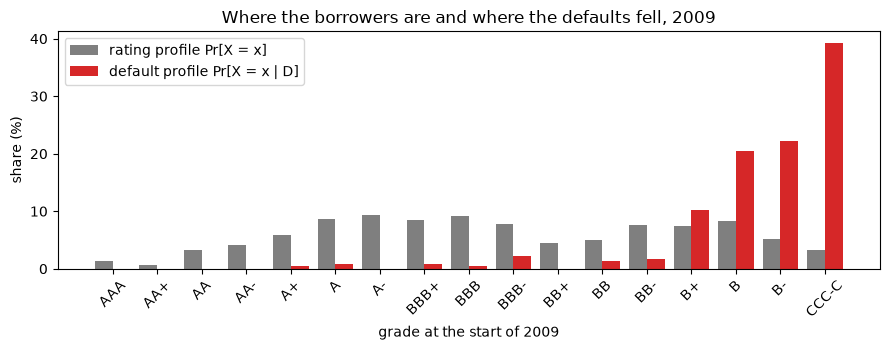

In [4]:
# Draw the 2009 rating profile and the default profile derived from the PD curve
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, 100 * profile0, 0.4, color="tab:gray", label="rating profile Pr[X = x]")
ax.bar(x + 0.2, 100 * default0, 0.4, color="tab:red", label="default profile Pr[X = x | D]")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grade at the start of 2009")
ax.set_ylabel("share (%)")
ax.set_title("Where the borrowers are and where the defaults fell, 2009")
ax.legend()
fig.tight_layout()
plt.show()

The rating profile is spread over the whole scale, with no grade above 9.3% of the borrowers, while the default profile is pushed to the right: B+, B, B- and CCC-C hold 92% of the defaults and 24% of the borrowers. The distance between the two bar sets is what the accuracy ratio of 0.8271 summarises, and the two descriptions are tied by the identities of the step, so knowing the profile and the PD curve fixes the default profile. The figure does not show the PD curve itself, only the two distributions it connects; with six of the 17 raw default rates equal to zero, the curve read directly from the counts is the next problem.

### Step 2: smoothing the curve by quasi moment matching

The raw default rate of 2009 is zero in six of the 17 grades, so a likelihood ratio built on it is zero or infinite there, and a PD of zero is no use as a curve. Quasi moment matching (QMM, appendix A of Tasche) fits the robust logistic curve

$$\Pr[D \mid X = x] = \frac{1}{1 + \exp\bigl(\alpha + \beta\,\Phi^{-1}(\tilde F_N(x))\bigr)}$$

with $\tilde F_N$ the average of the survival distribution function and its left-continuous version (A.9), choosing $\alpha$ and $\beta$ so that the unconditional PD and the accuracy ratio hit their targets.

The next cell calls `qmm` with the 2009 profile, PD, accuracy ratio and survival profile and prints the fitted constants.

In [5]:
# Fit the QMM curve to the 2009 targets and check that it hits them
q0 = pc.qmm(profile0, pd0, ar0, survival_profile=survival0)
curve0 = np.array(q0["pd_curve"])

print("alpha =", round(q0["alpha"], 4), "| beta =", round(q0["beta"], 4))
print("PD of the curve:", f"{100 * pc.unconditional_pd(curve0, profile0):.4f}%",
      "| accuracy ratio of the curve:", round(pc.accuracy_ratio_from_curve(curve0, profile0), 4))
print("increasing in the grade:", bool(np.all(np.diff(curve0) > 0)))
for g in (0, grades.index("B")):
    print(grades[g], "| raw rate:", f"{100 * rate0[g]:.4f}%", "| QMM curve:", f"{100 * curve0[g]:.4f}%")

alpha = 5.2048 | beta = 2.1613
PD of the curve: 3.9932% | accuracy ratio of the curve: 0.8271
increasing in the grade: True
AAA | raw rate: 0.0000% | QMM curve: 0.0028%
B | raw rate: 9.9585% | QMM curve: 7.9992%


The next cell draws the raw 2009 default rates and the smoothed curve on a logarithmic axis, the six grades with a raw rate of zero marked at the bottom.

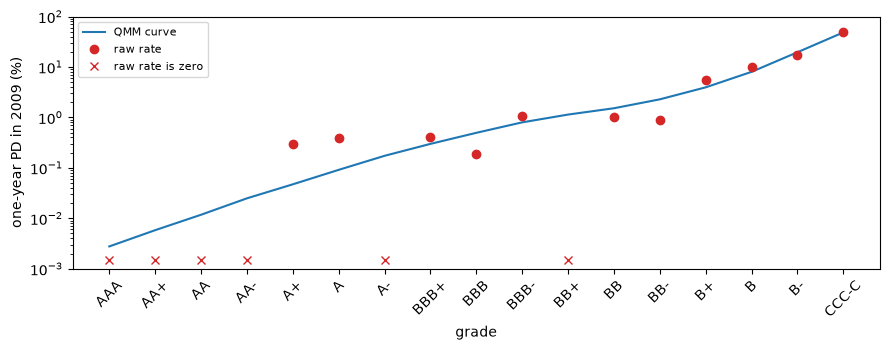

In [6]:
# Draw the raw default rates (points) and the QMM curve (line); zero rates sit at the bottom edge
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(x, 100 * curve0, color="tab:blue", label="QMM curve")
ax.plot(x[rate0 > 0], 100 * rate0[rate0 > 0], "o", color="tab:red", label="raw rate")
ax.plot(x[rate0 == 0], np.full((rate0 == 0).sum(), 1.5e-3), "x", color="tab:red", label="raw rate is zero")
ax.set_yscale("log")
ax.set_ylim(1e-3, 100)
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grade")
ax.set_ylabel("one-year PD in 2009 (%)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The curve is increasing in the grade, passes through the 2009 PD of 3.99% and the accuracy ratio of 0.8271 by construction, and gives AAA 0.0028% where the raw rate is zero and B 8.00% where the raw rate is 9.96%. The raw points zigzag, a grade with a few hundred borrowers cannot resolve a rate of a tenth of a percent, and the six grades marked at the bottom would have a likelihood ratio of zero or infinity. The figure shows the smoothing; it does not show that the curve is right for 2010, since it was fitted to 2009 targets, and carrying it to a new year is the subject of the next step.

### Step 3: carrying the curve when the new year's profile and PD are known

This is Tasche's case 1: the forecast profile $\Pr_1[X = x]$ and the forecast PD $p_1$ are known, and the question is which part of the model stays as it was. Each approach is an assumption about what is invariant:

- **Invariant default profile** (equation 4.2): $\Pr_1[X = x \mid D] = \Pr_0[X = x \mid D]$. With $p_1$ and the forecast profile it gives a raw survival profile, hence a forecast accuracy ratio by (3.7), and QMM fits the curve to that. It is proper only if $p_1 \Pr_0[X=x\mid D] \le \Pr_1[X=x]$ in every grade (4.6a).
- **Invariant accuracy ratio** (4.3): $\mathrm{AR}_1 = \mathrm{AR}_0$, with QMM on the forecast profile and PD.
- **Scaled PDs** (4.4): $\Pr_1[D \mid X = x] = c_{PD}\,\Pr_0[D \mid X = x]$ with $c_{PD} = p_1 / \sum_x \Pr_0[D \mid X = x]\,\Pr_1[X = x]$ (4.7a). Simple and widespread, and improper whenever a scaled PD exceeds one.
- **Scaled likelihood ratio** (4.5): $\lambda_1 = c_{LR}\,\lambda_0$, with $c_{LR}$ the root of $1 = \sum_x \Pr_1[X = x] / (p_1 + (1 - p_1)\,c_{LR}\,\lambda_0(x))$ (4.8a); the root exists and is unique, so the model is always proper.

Tasche's conclusion is that scaling the PDs is theoretically questionable and the scaled likelihood ratio and the invariant accuracy ratio perform much better.

The next cell runs the four approaches for 2010 and for 2011 and prints, for 2010, each one's constants and the PD and accuracy ratio it gives under the 2010 profile.

In [7]:
# The four case 1 approaches for both forecast years, and the constants of each in 2010
curves = {}
for yr, doc in years.items():
    o = doc["outputs"]
    profile1, pd1 = np.array(o["profile1"]), o["pd1"]
    a1 = pc.invariant_default_profile(default0, profile1, pd1)
    a2 = pc.invariant_accuracy_ratio(profile1, pd1, ar0)
    a3 = pc.scaled_pds(curve0, profile1, pd1)
    a4 = pc.scaled_likelihood_ratio(curve0, q0["pd"], profile1, pd1)
    curves[yr] = {"A1-idp": a1["pd_curve"], "A2-iar": a2["pd_curve"],
                  "A3-spd": a3["pd_curve"], "A4-slr": a4["pd_curve"]}
    if yr == 2010:
        consts = (a1, a2, a3, a4)
profile1, pd1 = np.array(o10["profile1"]), o10["pd1"]
a1, a2, a3, a4 = consts

print("forecast PD of 2010:", f"{100 * pd1:.2f}%", "| PD of 2009:", f"{100 * pd0:.2f}%")
print("A1: accuracy ratio implied", round(a1["accuracy_ratio_target"], 4))
print("A2: accuracy ratio kept at the 2009 value", round(ar0, 4))
print("A3: c_PD =", round(a3["c_pd"], 4), "| largest scaled PD:", f"{100 * max(a3['pd_curve']):.1f}%")
print("A4: c_LR =", round(a4["c_lr"], 4), "| bracket:", [round(v, 4) for v in a4["bracket"]])
print(f"{'approach':10s}{'PD under the 2010 profile':>34s}{'accuracy ratio':>24s}")
for key, curve in curves[2010].items():
    implied = 100 * pc.unconditional_pd(curve, profile1)
    print(f"{key:10s}{implied:33.4f}%{pc.accuracy_ratio_from_curve(curve, profile1):24.4f}")

forecast PD of 2010: 1.14% | PD of 2009: 3.99%
A1: accuracy ratio implied 0.7935
A2: accuracy ratio kept at the 2009 value 0.8271
A3: c_PD = 0.2642 | largest scaled PD: 12.8%
A4: c_LR = 1.4081 | bracket: [0.0188, 1.5494]
approach           PD under the 2010 profile          accuracy ratio
A1-idp                               1.1409%                  0.7935
A2-iar                               1.1409%                  0.8271
A3-spd                               1.1409%                  0.8100
A4-slr                               1.1409%                  0.8451


The next cell draws the 2009 curve and the four curves for 2010 on a logarithmic axis.

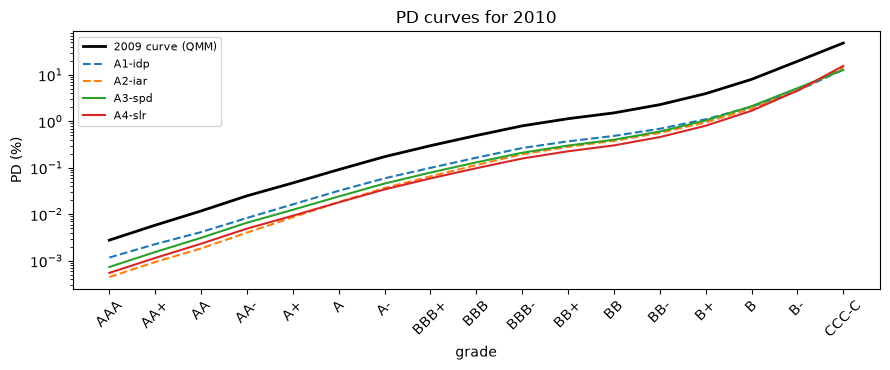

In [8]:
# Draw the 2009 curve and the four approaches' curves for 2010
x = np.arange(len(grades))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, 100 * curve0, color="black", linewidth=2, label="2009 curve (QMM)")
for key, style in (("A1-idp", "--"), ("A2-iar", "--"), ("A3-spd", "-"), ("A4-slr", "-")):
    ax.plot(x, 100 * np.array(curves[2010][key]), style, label=key)
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(grades, rotation=45)
ax.set_xlabel("grade")
ax.set_ylabel("PD (%)")
ax.set_title("PD curves for 2010")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Every approach reproduces the forecast PD of 1.14% under the 2010 profile, which is what case 1 gives them to fit, and they differ in shape. All four curves lie below the 2009 curve, because 2010 was a better year, but not by the same amount: scaling the PDs multiplies every grade by the same c_PD = 0.2642, while the scaled likelihood ratio, with c_LR = 1.4081, gives the best grades the lowest PDs of the four and CCC-C the highest. The accuracy ratios they imply, 0.7935, 0.8271, 0.8100 and 0.8451, show that the approaches disagree on how well the system separates borrowers in 2010. The figure cannot say which curve is right, only where the approaches part; the next steps test their shape and price their difference.

### Step 4: when less is known

Two further cases drop information. In **case 2** only the forecast PD is known: the invariant likelihood ratio (equations 4.10 and 4.11, Elkan's change in base rate) keeps $\lambda_0$ and moves only the base rate, $\Pr_1[D \mid X = x] = p_1 / (p_1 + (1 - p_1)\lambda_0(x))$. In **case 3** only the forecast profile is known: the **invariant PD curve** (4.12) keeps the 2009 curve unchanged and lets the forecast PD follow, $p_1 = \sum_x \Pr_0[D \mid X = x]\Pr_1[X = x]$ (4.13). Tasche warns (section 4.4.1) that this carries the estimation year's unconditional PD into the forecast.

The next cell computes both for 2010 and prints the PD each implies under the observed 2010 profile.

In [9]:
# Case 2 (only the PD known) and case 3 (the 2009 curve kept) and the PD each implies in 2010
b1 = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=pd1)
c1 = pc.invariant_pd_curve(curve0, profile1)
implied_b1 = pc.unconditional_pd(b1["pd_curve"], profile1)

print("observed forecast PD of 2010:", f"{100 * pd1:.2f}%")
print("B1: PD given to the approach", f"{100 * pd1:.2f}%",
      "| PD under the observed profile:", f"{100 * implied_b1:.2f}%")
print("C1: PD that follows (4.13)", f"{100 * c1['pd']:.2f}%", "| PD of 2009:", f"{100 * pd0:.2f}%")
print("the 2009 curve unchanged against the observed PD, ratio:", round(c1["pd"] / pd1, 2))

observed forecast PD of 2010: 1.14%
B1: PD given to the approach 1.14% | PD under the observed profile: 1.55%
C1: PD that follows (4.13) 4.32% | PD of 2009: 3.99%
the 2009 curve unchanged against the observed PD, ratio: 3.78


Case 2 shows what the profile is for. Told only the PD, the invariant likelihood ratio gives 1.55% under the observed 2010 profile instead of the 1.14% it was given: without the profile it cannot be consistent with it. Case 3 shows the cost of doing nothing: the 2009 curve, applied to the 2010 profile, forecasts a PD of 4.32% against an observed 1.14%, 3.8 times as much. A validator who finds the same curve in use a year later, and a profile that has improved, is looking at a calibration that overstates the PD by this factor, and the next step puts a price on it.

### Step 5: testing the shape of the implied default profile

A calibrated curve implies where the defaults fall on the grades: the implied default profile $q_x = n_x\,\mathrm{PD}_x / \sum_t n_t\,\mathrm{PD}_t$ (equation 3.5b). The engine's registered test `pd.default_profile` compares the observed default counts with it by Pearson's chi-square, $T = \sum_x (d_x - D q_x)^2 / (D q_x)$ with $D$ the number of defaults, and, because expected counts are small in the good grades, takes the p-value from 100,000 multinomial samples (seed 2013). It sees the shape of the curve and not its level. The test needs the grade counts, which the source does not allow to publish, so this cell reads the committed rows (9 approaches, two years) and does not recompute them.

In [10]:
# Read the committed default-profile tests of the nine approaches in 2010 and 2011
tests = {}
for yr, doc in years.items():
    tests[yr] = {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "pd.default_profile"}
keys = list(tests[2010])
print("baked by riskvalidation", years[2010]["provenance"]["riskvalidation_version"],
      "| installed", md.version("riskvalidation"))

print(f"{'approach':10s}{'T 2010':>9s}{'p 2010':>9s}{'light':>8s}{'T 2011':>9s}{'p 2011':>9s}{'light':>8s}")
for key in keys:
    a, b = tests[2010][key], tests[2011][key]
    print(f"{key:10s}{a['statistic']:9.2f}{a['p_value']:9.4f}{a['light']:>8s}",
          f"{b['statistic']:9.2f}{b['p_value']:9.4f}{b['light']:>8s}")

baked by riskvalidation 1.0.1 | installed 1.0.1
approach     T 2010   p 2010   light   T 2011   p 2011   light
A1-idp        31.40   0.0458   amber      6.32   0.7817   green
A2-iar        24.42   0.0791   green      4.51   0.8910   green
A3-spd        33.70   0.0425   amber     11.79   0.3696   green
A4-slr        21.47   0.1115   green      5.55   0.8199   green
B1-ilr        22.67   0.1011   green      5.71   0.8076   green
C1-ipc        33.70   0.0425   amber     11.79   0.3696   green
C2-ls         36.87   0.0335   amber     10.77   0.4215   green
C3-chi2       39.02   0.0293   amber      9.44   0.5095   green
C4-ilr        39.14   0.0291   amber      9.36   0.5153   green


The next cell draws the p-value of the default-profile test for each of the nine approaches in both years, with the 5% line.

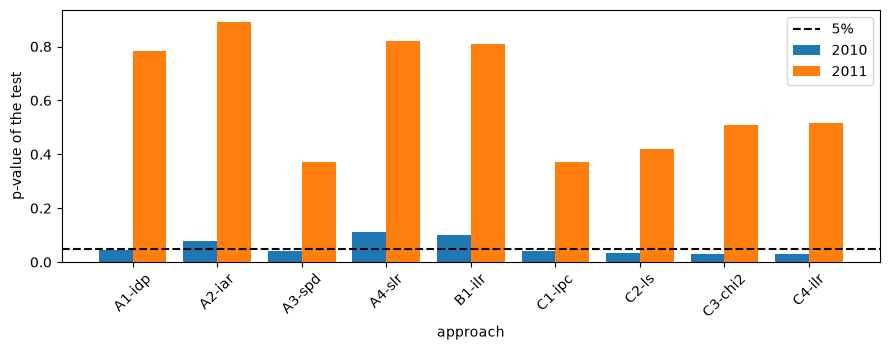

In [11]:
# Draw the p-value of the default-profile test of each approach, both years
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [tests[2010][k]["p_value"] for k in keys], 0.4, color="tab:blue", label="2010")
ax.bar(x + 0.2, [tests[2011][k]["p_value"] for k in keys], 0.4, color="tab:orange", label="2011")
ax.axhline(0.05, color="black", linestyle="--", label="5%")
ax.set_xticks(x)
ax.set_xticklabels(keys, rotation=45)
ax.set_xlabel("approach")
ax.set_ylabel("p-value of the test")
ax.legend()
fig.tight_layout()
plt.show()

In 2010 the shape test separates the approaches: the invariant default profile (p = 0.0458) and the scaled PDs (p = 0.0425) fall below 5% and are amber, while the scaled likelihood ratio (p = 0.1115) and the invariant accuracy ratio (p = 0.0791) stay green, and the cases that carry the 2009 curve or its likelihood ratio are amber as well. In 2011 all nine approaches are green, with p from 0.37 to 0.89. The p-values come from 100,000 multinomial draws with a Monte Carlo error of about 0.0007. The test sees the shape of the curve and not its level, so it cannot tell a curve that is too high everywhere from a good one; the risk weight of the next step carries the level.

### Step 6: the price of the choice in IRB risk weight

A PD curve is an input to capital. The artifact commits, for each approach, the average IRB risk weight of the forecast portfolio, one unit of exposure per obligor, with the Basel III corporate function, an LGD of 45% (F-IRB senior unsecured, financial institutions, CRE32.6), a maturity of 2.5 years and the PD floor of 0.05% (CRE32.4); https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27.

The next cell recomputes it with the engine's `capital_requirement` for the six curves of this notebook in both years, and prints how much more capital the unchanged 2009 curve asks than the scaled likelihood ratio.

In [12]:
# Average IRB risk weight of each forecast portfolio under the six curves, both years
cfg = o10["irb"]
weights = {}
for yr, doc in years.items():
    o = doc["outputs"]
    prof, p1 = np.array(o["profile1"]), o["pd1"]
    six = dict(curves[yr])
    six["B1-ilr"] = pc.invariant_likelihood_ratio(curve0, q0["pd"], pd_1=p1)["pd_curve"]
    six["C1-ipc"] = pc.invariant_pd_curve(curve0, prof)["pd_curve"]
    required = {}
    for key, curve in six.items():
        required[key] = [irb.capital_requirement(cfg["asset_class"], float(p), cfg["lgd"], maturity=cfg["maturity"],
                                                 regime=cfg["regime"]).risk_weight for p in curve]
    weights[yr] = {k: float(np.sum(prof * np.array(v))) for k, v in required.items()}

print(f"{'approach':10s}{'2010 risk weight':>26s}{'2011 risk weight':>26s}")
for key in weights[2010]:
    print(f"{key:10s}{100 * weights[2010][key]:25.1f}%{100 * weights[2011][key]:25.1f}%")
for yr in years:
    stale = weights[yr]["C1-ipc"] / weights[yr]["A4-slr"] - 1.0
    case1 = [weights[yr][k] for k in ("A1-idp", "A2-iar", "A3-spd", "A4-slr")]
    spread = max(case1) / min(case1) - 1.0
    print(yr, "| unchanged 2009 curve costs more:", f"{100 * stale:.1f}%",
          "| spread of the case 1 approaches:", f"{100 * spread:.1f}%")

approach            2010 risk weight          2011 risk weight
A1-idp                         60.9%                     51.6%
A2-iar                         57.3%                     49.4%
A3-spd                         58.8%                     53.5%
A4-slr                         55.0%                     50.5%
B1-ilr                         61.6%                     53.3%
C1-ipc                         90.7%                     92.6%
2010 | unchanged 2009 curve costs more: 64.8% | spread of the case 1 approaches: 10.7%
2011 | unchanged 2009 curve costs more: 83.3% | spread of the case 1 approaches: 8.3%


The next cell draws the risk weight each approach gives to the 2010 and 2011 portfolios.

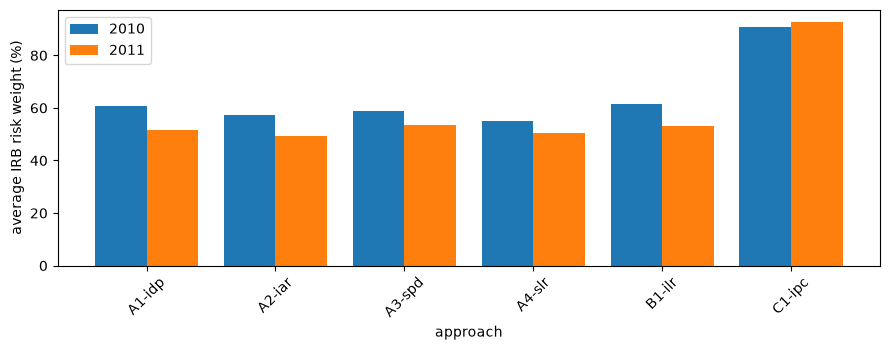

In [13]:
# Draw the average IRB risk weight by approach, both years
names = list(weights[2010])
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(x - 0.2, [100 * weights[2010][k] for k in names], 0.4, color="tab:blue", label="2010")
ax.bar(x + 0.2, [100 * weights[2011][k] for k in names], 0.4, color="tab:orange", label="2011")
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=45)
ax.set_xlabel("approach")
ax.set_ylabel("average IRB risk weight (%)")
ax.legend()
fig.tight_layout()
plt.show()

The four approaches that know the new profile and PD price the 2010 portfolio between 55.0% and 60.9% of risk weight, a spread of 10.7%, and 8.3% in 2011; the choice among them is worth a few points of capital. Carrying the 2009 curve unchanged is a different order of cost, 90.7% in 2010 and 92.6% in 2011, which is 64.8% and 83.3% more capital than the scaled likelihood ratio. The figure shows the asymmetry: the validator who asks whether a calibration was updated is asking about the largest item of the table, and the one who asks which update was used about the smallest.

### Step 7: against Tasche's printed tables

Tasche prints the smoothed 2009 curve in percent (Table 5, to three decimals), the forecast curves of the four case 1 approaches with the p-values of the default-profile test (Table 7, four decimals for the curves) and the forecast PDs of case 3 (Table 8). The artifact commits each printed cell beside the recomputation (`golden`).

The next cell compares the printed Table 5 with the QMM curve of Step 2 and the printed Table 7 curves with the curves of Step 3 in percentage points, then reads the committed p-values and the case 3 PDs.

In [14]:
# Tasche's printed Tables 5 and 7 against these curves, then the committed p-values and PDs
golden = o10["golden"]
printed5 = np.array([row["printed"] for row in golden["table5"]])
gap5 = float(np.abs(100 * curve0 - printed5).max())
print("Table 5, largest gap in points:", round(gap5, 4))
for key in ("A1-idp", "A2-iar", "A3-spd", "A4-slr"):
    printed = np.array([row["printed"] for row in golden["table7"][key]])
    gap = float(np.abs(100 * np.array(curves[2010][key]) - printed).max())
    print(f"Table 7 {key}: {printed.size} cells, largest gap in points {gap:.4f}")
print(f"{'approach':10s}{'printed p (%)':>22s}{'committed (%)':>22s}")
for row in golden["table7_p_values"]:
    print(f"{row['approach']:10s}{row['printed_pct']:22.2f}{row['ours_pct']:22.2f}")
for row in golden["table8"]:
    print(row["approach"], "| printed PD", row["printed_pct"], "% | committed", row["ours_pct"], "%")

Table 5, largest gap in points: 0.0013
Table 7 A1-idp: 17 cells, largest gap in points 0.0001
Table 7 A2-iar: 17 cells, largest gap in points 0.0002
Table 7 A3-spd: 17 cells, largest gap in points 0.0003
Table 7 A4-slr: 17 cells, largest gap in points 0.0005
approach           printed p (%)         committed (%)
A1-idp                      4.60                  4.58
A2-iar                      8.00                  7.91
A3-spd                      4.00                  4.25
A4-slr                     11.30                 11.15
C1-ipc | printed PD 4.32 % | committed 4.318 %
C2-ls | printed PD 4.8 % | committed 4.799 %
C3-chi2 | printed PD 5.35 % | committed 5.347 %
C4-ilr | printed PD 5.38 % | committed 5.377 %


## Results

**Answer:** carry the 2009 curve with an approach that uses the new year's profile and PD, never unchanged. The 2010 forecast PD is 1.14%, against 3.99% in 2009; the 2009 curve unchanged forecasts 4.32% under the 2010 profile, 3.8 times the observed PD, and gives the 2010 portfolio an average IRB risk weight of 90.7% against 55.0% under the scaled likelihood ratio: 64.8% more capital in 2010 and 83.3% in 2011. The four approaches that know the new profile and PD differ by 10.7% in risk weight in 2010 (55.0% scaled likelihood ratio, 57.3% invariant accuracy ratio, 58.8% scaled PDs, 60.9% invariant default profile), and the shape test sides with the first two (p = 0.1115 and 0.0791) against the last two (p = 0.0458 and 0.0425).

- **The 2009 model is a consistent joint distribution.** The engine derives the unconditional PD (3.9932%) and the accuracy ratio (0.8271) from the profile and the grade default rates. Six of the 17 raw default rates are zero, so a likelihood ratio built on them is undefined and the curve has to be smoothed.
- **QMM.** With alpha = 5.2048 and beta = 2.1613 the smoothed curve hits the 2009 targets. It gives AAA 0.0028% where the raw rate is 0, B 7.9992% where the raw rate is 9.9585%, and is increasing in the grade.
- **Case 1, 2010.** Scaling the PDs multiplies every grade by c_PD = 0.2642; the scaled likelihood ratio has c_LR = 1.4081. The accuracy ratios of the four approaches are 0.7935 (invariant default profile), 0.8271 (kept from 2009), 0.8100 (scaled PDs) and 0.8451 (scaled likelihood ratio).
- **When less is known.** With only the PD (case 2), the invariant likelihood ratio gives 1.55% under the observed 2010 profile instead of the 1.14% it was given.
- **Against the print.** The four Table 7 curves are within 0.0005 percentage points of Tasche's printed values in every grade, and Table 5's largest gap is 0.0013 points.

What this notebook does not show: the comparison of all nine approaches on the forecast against the observed PD (notebook 09), or how a calibration error propagates through the IRB formula (notebook 07).

## Summary

- A rating model is a joint distribution of grade and default; the PD curve, the two conditional profiles and the likelihood ratio are equivalent descriptions and the engine derives one from another.
- A curve with zero rates is smoothed by QMM before it is carried to a new year.
- With the forecast profile and PD known, four approaches carry the curve; they differ in what they keep invariant and their curves differ in shape, not in the forecast PD. Scaling the PDs is the simplest and the least defensible.
- Keeping the old curve unchanged forecasts a PD 3.8 times the observed one and costs 65% to 83% more capital than the scaled likelihood ratio.
- The default-profile test sees the shape of a curve, not its level; Tasche's printed tables are the check on the recomputation.

**What to try next.** Replace the forecast PD of Step 3 by the 2009 PD and see which approaches keep the curve and which move it; then read notebook 06.

## References

- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), 63-103, equations 3.5, 3.7, 3.8, 4.2 to 4.15 and appendix A, Tables 6 to 8; arXiv 1212.3716. https://doi.org/10.21314/jcr.2013.169
- BCBS, Basel Framework, CRE32, IRB approach: risk-weighted asset calculation (LGD, maturity and PD floor). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Elkan, C. (2001), The foundations of cost-sensitive learning, IJCAI, for the change in base rate (equation 4.11).
- Pearson, K. (1900), On the criterion that a given system of deviations from the probable in the case of a correlated system of variables is such that it can be reasonably supposed to have arisen from random sampling, Philosophical Magazine 50(302), 157-175.